In [1]:
# Data Loading & Initial Inspection
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('netflix_titles.csv')

# Understand column behaviour by seeing first 5 rows of the dataset
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
# Data Profiling & Structural Analysis
# Shape of dataset
print("Dataset Shape:", df.shape)

# Dataset Info
print("\n--- Dataset Structural Info ---")
df.info()

Dataset Shape: (8807, 12)

--- Dataset Structural Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [3]:
# Missing Value Analysis
# Check number of null values each column
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [4]:
# Data Cleaning
# Fill empty boxes with "Unknown"
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Drop rows containing fewer empty boxes
df = df.dropna(subset=['date_added', 'rating', 'duration'])

# Check if data is cleaned
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

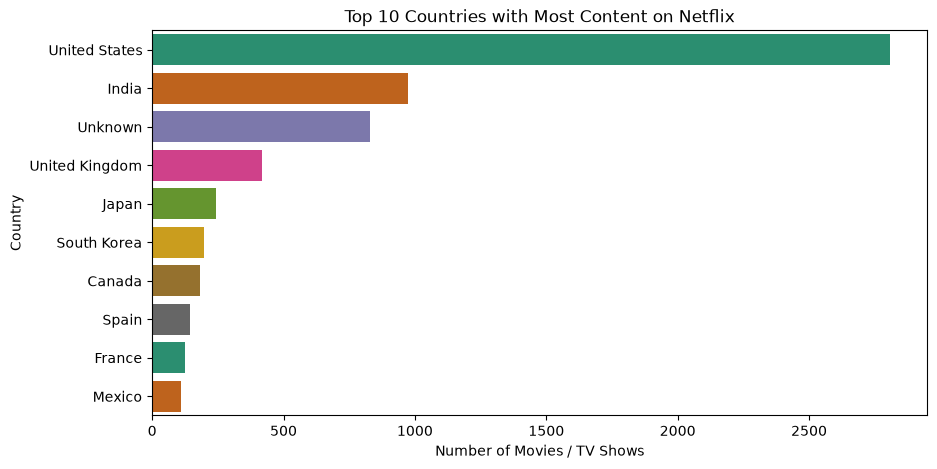

In [6]:
# TASK 1: Understanding what content is available in different countries
# Count content number according to country (Top 10 countries)
top_countries = df['country'].value_counts().head(10)

# Visualize bar chart of top 10 countries
plt.figure(figsize=(10,5))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette='Dark2', legend=False)

# Set title and label
plt.title('Top 10 Countries with Most Content on Netflix')
plt.xlabel('Number of Movies / TV Shows')
plt.ylabel('Country')

# Show graph
plt.show()

In [7]:
# TASK 2: Identifying similar content by matching text-based features
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Discard english stop-words (like: the, is, and) from description, and convert into numbers
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['description'])

# Measure Cosine Similarity matrix
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Create mechanism to find index using movie title
indices = pd.Series(df.index, index=df['title']).drop_duplicates()

# Create function to find similar movie
def get_recommendations(title, cosine_sim=cosine_sim):
    # Find input movie index
    idx = indices[title]
    
    # List down movie similarity score
    sim_scores = list(enumerate(cosine_sim[idx]))
    
    # Arrange movies with higher similarity based on score (Descending order)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # Take 10 similar movies (Excluding the first one, because the first one is the movie itself)
    sim_scores = sim_scores[1:11]
    
    # Find movie indices
    movie_indices = [i[0] for i in sim_scores]
    
    # Return the names of top 10 movies
    return df['title'].iloc[movie_indices]

# Test and check: Which movies are similar to 'Transformers Prime' movie
print("Recommendations for 'Transformers Prime':")
print(get_recommendations('Transformers Prime'))


Recommendations for 'Transformers Prime':
1482      Transformers: War for Cybertron: Earthrise
2192         Transformers: War For Cybertron Trilogy
4652                Transformers: Robots in Disguise
4927                                  Beyond Skyline
6445                                  Chappaquiddick
2525                             Parasyte: The Maxim
58      Naruto Shippûden the Movie: The Will of Fire
2549                                      John Henry
4500                          The Night Comes for Us
936                      Miniforce: Super Dino Power
Name: title, dtype: str


In [8]:
# TASK 3: Network analysis of Actors / Directors and find interesting insights
# Filter out rows where director or cast is unknown
df_network = df[(df['director'] != 'Unknown') & (df['cast'] != 'Unknown')].copy()

# Create a list to store director and actor pairs
relations = []

for idx, row in df_network.iterrows():
    director = row['director'].strip()
    # Split actors as there can be multiple actors in one movie
    actors = [actor.strip() for actor in row['cast'].split(',')]
    for actor in actors:
        relations.append((director, actor))

# Convert the pairs into a DataFrame
df_relations = pd.DataFrame(relations, columns=['Director', 'Actor'])

# Find the top 10 most frequent Director-Actor duos
top_duos = df_relations.value_counts().head(10)

print("Top 10 Director-Actor Duos on Netflix:")
print(top_duos)

Top 10 Director-Actor Duos on Netflix:
Director           Actor             
Rajiv Chilaka      Julie Tejwani         17
                   Jigna Bhardwaj        17
                   Rajesh Kava           17
                   Rupa Bhimani          16
                   Vatsal Dubey          15
                   Mousam                12
                   Swapnil               12
Suhas Kadav        Saurav Chakraborty     8
Toshiya Shinohara  Kappei Yamaguchi       7
                   Satsuki Yukino         7
Name: count, dtype: int64


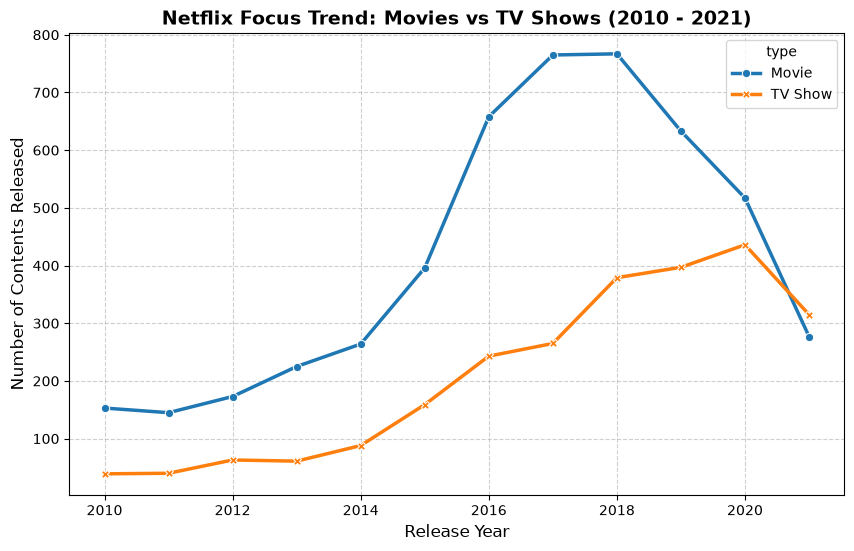

In [9]:
# TASK 4: Does Netflix has more focus on TV Shows than movies in recent years?
# Filter data of recent years (2010 to 2021)
df_recent = df[df['release_year'] >= 2010]

# Create Pivot Table showing number of movies and shows per year
trend = df_recent.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# Visualize a line graph
plt.figure(figsize=(10,6))
sns.lineplot(data=trend, markers=True, dashes=False, linewidth=2.5)

# Set title, label and legend
plt.title("Netflix Focus Trend: Movies vs TV Shows (2010 - 2021)", fontsize=14, fontweight='bold')
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Contents Released", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) 

# Show graph
plt.show()